In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error as mse, mean_absolute_error as mae, root_mean_squared_error as rmse
from itertools import product
import lightgbm as lgb
import optuna
from sklearn.model_selection import KFold

optuna.logging.set_verbosity(optuna.logging.WARNING)

cwd = Path.cwd()
root = cwd.parent

data = pd.read_csv(str(cwd / 'processed_added_features.csv'))
numeric = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
categorical = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP',
                          'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
engineered = ['workers_per_1000_sqft', 'weekly_floor_area_hours', 'heated_floor_area', 
              'cooled_floor_area', 'heating_area_degree_days', 'cooling_area_degree_days',
              'NFLOOR_CEILING_HEIGHT', 'HDD65_CDD65', 'COOLP_HEATP']
data = data.drop(columns='MAINHT__missing') # duplicate column
data = data.rename(columns={'Unnamed: 0':'ROW_ID'}) # default index
data = data.set_index('ROW_ID')

processed = data.copy(True)

In [11]:
# Condensing dummies. Lightgbm handles categoricals natively.
for cat in categorical:
    cols = None
    if cat == 'NFLOOR':
        suffixes = ['__code','__withheld','__missing','__15','__10_to_14']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    elif cat == 'PUBCLIM':
        suffixes = ['__code','__withheld','__missing']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    else:
        suffixes = ['__code','__missing']
        cols = [c for c in data.columns if cat in c and any(s in c for s in suffixes)]
    processed[cat] = pd.from_dummies(data[cols], sep='__', default_category='UNKNOWN')[cat].astype('category')

processed['CENDIV_PUBCLIM'] = pd.from_dummies(data[[c for c in data.columns if 'CENDIV_PUBCLIM' in c]], sep='_', default_category='UNKNOWN').astype('category')

In [12]:
# features, target, train/val/test splits
X = processed[numeric + categorical + engineered]
y = np.log1p(processed[['MFBTU']]) # log transform target due to heavy right skewness. not strictly necessary for LGBM but may help with tree splits

X_train = X[data['split']=='train']
y_train = y[data['split']=='train']
X_val = X[data['split']=='validation']
y_val = y[data['split']=='validation']
X_test = X[data['split']=='test']
y_test = y[data['split']=='test']

In [13]:
# Initial, unoptimized model
model = lgb.LGBMRegressor()
model.fit(X_train, y_train, eval_X=X_val, eval_y=y_val)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [14]:
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

print("Training RMSE: ", np.sqrt(mse(train_pred, y_train)))
print("Training R squared: ", r2_score(y_train, train_pred))
print("Validation RMSE: ", np.sqrt(mse(val_pred, y_val)))
print("Validation R squared: ", r2_score(y_val, val_pred))

Training RMSE:  0.34897805213433397
Training R squared:  0.9729776724472841
Validation RMSE:  0.5871664048763152
Validation R squared:  0.9219619875343239


In [ ]:
# hyperparameter optimization, simple grid search
seed = 1
# all of the possible values we iterate over to find the best performance on validation
param_grid = {
    'num_leaves': [3, 5, 7, 15, 31, 63, 97],
    'min_child_samples': [10, 20, 40, 80],
    'feature_fraction': [.7, .85, 1.0],
    'lambda_l2': [0, 0.5, 1],
    'learning_rate': [0.15, 0.1, 0.05]
}

base_params = {
    'metric': 'l2', # ie MSE
    'objective': 'regression',
    # 'learning_rate': 0.1,
    'seed': seed,
    'deterministic': True,
    'force_col_wise': True,
    'verbose': -1
}
# constructs the parameter configurations
keys = list(param_grid)
configs = [{**base_params, **dict(zip(keys, vals))} for vals in product(*param_grid.values())]

In [ ]:
def score(true:np.ndarray, pred:np.ndarray):
    """Returns RMSE, MAE, and R Squared for predictions"""
    return {
        'rmse': rmse(true, pred),
        'mae': mae(true, pred),
        'r2_score': r2_score(true, pred)
    }

In [ ]:
def search(configs: list[dict], 
           x_train:pd.DataFrame, 
           y_train:pd.DataFrame,
           x_val:pd.DataFrame,
           y_val:pd.DataFrame
           ):
    """Iterates through parameter configurations and returns summary of config scores (RMSE, MAE, and R Squared) and best configuration based on RMSE"""
    summary = []
    best = 0
    dtrain = lgb.Dataset(x_train, y_train)
    dval = lgb.Dataset(x_val, y_val)
    for cid, params in enumerate(configs):
        s = lgb.train(
            train_set=dtrain, 
            params=params, 
            valid_sets=[dval],
            num_boost_round=200,
            callbacks=([lgb.early_stopping(stopping_rounds=100, verbose=False)])
            )            
        pred = s.predict(X_val)
        summary.append(score(y_val, pred))
        if summary[cid]['rmse'] < summary[best]['rmse']:
            best = cid
    return summary, best

In [18]:
scores, best = search(configs, X_train, y_train, X_val, y_val)

In [19]:
# best hyperparameter configuration on grid search
min_s = 0
for i, s in enumerate(scores):
    if s['rmse'] < scores[min_s]['rmse']:
        min_s = i
configs[min_s]

{'metric': 'l2',
 'objective': 'regression',
 'seed': 1,
 'deterministic': True,
 'force_col_wise': True,
 'verbose': -1,
 'num_leaves': 7,
 'min_child_samples': 80,
 'feature_fraction': 0.85,
 'lambda_l2': 0.5,
 'learning_rate': 0.1}

1st optimized config:

- Learning rate = 0.1
- Number of leaves = 7
- Min child samples = 80
- Feature fraction = 85%
- L2 Lambda = .5

In [20]:
# Refit on best grid search config
train = lgb.Dataset(X_train, y_train)
model_opt = lgb.train(train_set=train, params=configs[best])
opt_pred_train = model_opt.predict(X_train)
opt_pred_val = model_opt.predict(X_val)

print(f"""Train scores: 
{score(y_train, opt_pred_train)}

Val scores:
{score(y_val, opt_pred_val)}
""")

Train scores: 
{'rmse': 0.5300070378438629, 'mae': 0.38694009547300895, 'r2_score': 0.9376710517506183}

Val scores:
{'rmse': 0.5618515724312673, 'mae': 0.41916176921924436, 'r2_score': 0.9285459247743539}



<Axes: title={'center': 'Feature importance'}, xlabel='Feature importance', ylabel='Features'>

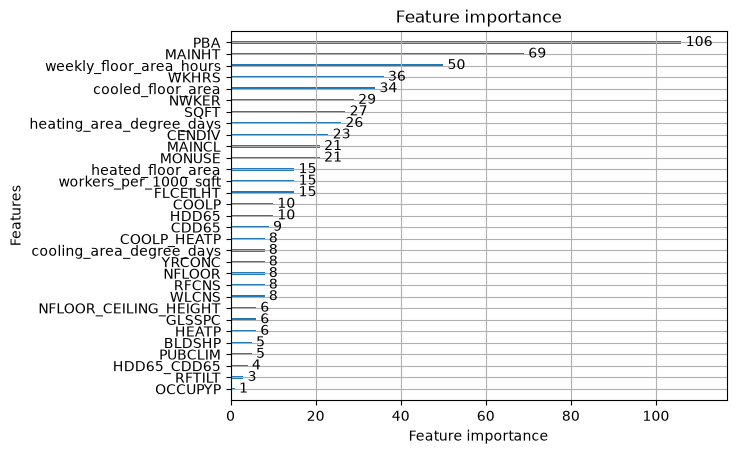

In [21]:
# plotting feature importances of the grid optimized model
lgb.plot_importance(model_opt, importance_type='split', precision=2)

In [22]:
# 2nd optimization attempt
# increase boosting rounds, decrease learning rate
# expand l2 regularization
# introduce l1 regularization
# introduce row subsampling
# use 5 fold cross validation to help prevent overfitting on validation rows

study = optuna.create_study(direction='minimize')
# 5 fold CV, using all training and validation rows. Test is still held out
X_cv = pd.concat([X_train, X_val], ignore_index=True)
y_cv = pd.concat([y_train, y_val], ignore_index=True)
folds = list(KFold(n_splits=5, shuffle=True, random_state=seed).split(X_cv, y_cv))

def objective(trial):
    params = {
        # fixed
        'metric': 'l2',
        'objective': 'regression',
        'seed': seed,
        'deterministic': True,
        'force_col_wise': True,
        'verbose': -1,
        'max_bin': 511,
        # to optimize
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.5, 1.0),
        'lambda_l2': trial.suggest_float('lambda_l2', 1, 10),
        'lambda_l1': trial.suggest_float('lambda_l1', 1, 2),
        'num_leaves': trial.suggest_int('num_leaves', 3, 15),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 60),
        'extra_trees': trial.suggest_categorical('extra_trees', [False, True])
    }

    cvtrain = lgb.Dataset(data = X_cv, label = y_cv)

    lcv = lgb.cv(
        params = params,
        train_set = cvtrain,
        folds = folds,
        num_boost_round = 5000,
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )

    return min(lcv['valid l2-mean'])
# queuing the best config from grid search for performance comparison on the 5 fold approach
study.enqueue_trial({
    'learning_rate': .1,
    'num_leaves': 7,
    'min_child_samples': 80,
    'feature_fraction': .85,
    'lambda_l2': .5
})
study.optimize(objective, n_trials=100)

print('Best CV RMSE =', study.best_value)
print('Best configs =', study.best_params)

c:\Users\xtxk118\Projects\repo_clones\datasci207_final_project\.venv\Lib\site-packages\optuna\trial\_trial.py:642: UserWarning: Fixed parameter lambda_l2 with value 0.5 is out of range for distribution FloatDistribution(high=10.0, log=False, low=1.0, step=None).
  optuna_warn(
c:\Users\xtxk118\Projects\repo_clones\datasci207_final_project\.venv\Lib\site-packages\optuna\trial\_trial.py:642: UserWarning: Fixed parameter min_child_samples with value 80 is out of range for distribution IntDistribution(high=60, log=False, low=5, step=1).
  optuna_warn(


Best CV RMSE = 0.3398437977691714
Best configs = {'learning_rate': 0.011993295504875932, 'feature_fraction': 0.8251835567204013, 'lambda_l2': 2.32808220898706, 'lambda_l1': 1.1893097542206308, 'num_leaves': 6, 'min_child_samples': 21, 'extra_trees': True}


In [23]:
print(f"""Best parameters: 
{study.best_params}""")

Best parameters: 
{'learning_rate': 0.011993295504875932, 'feature_fraction': 0.8251835567204013, 'lambda_l2': 2.32808220898706, 'lambda_l1': 1.1893097542206308, 'num_leaves': 6, 'min_child_samples': 21, 'extra_trees': True}


Optuna optimized final model configs:
- Learning rate = 0.012
- Feature fraction = 0.83
- Lambda L2 = 2.33
- Lambda L1 = 1.19
- Number of leaves = 6
- Min child samples = 21
- Extra trees = True

In [24]:
# final CV fit based on optuna results
final_config = {
        'metric': 'l2',
        'objective': 'regression',
        'seed': seed,
        'deterministic': True,
        'force_col_wise': True,
        'verbose': -1,
        'max_bin': 511,
        **study.best_params}

def fit_cv_boosters(x, y, folds, params):
    lcv = lgb.cv(
        params=params,
        train_set=lgb.Dataset(data=x, label=y),
        folds=folds,
        num_boost_round=5000,
        return_cvbooster=True,
        callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)]
    )

    cvbooster = lcv['cvbooster']
    best_iter = int(np.argmin(lcv['valid l2-mean']) + 1)

    oof_preds = np.zeros(len(x))
    train_r2_scores = []
    val_r2_scores = []

    # out of fold predictions, r squared
    for (train_idx, val_idx), booster in zip(folds, cvbooster.boosters):
        pred_train = booster.predict(x.iloc[train_idx], num_iteration=best_iter)
        pred_val = booster.predict(x.iloc[val_idx], num_iteration=best_iter)
        oof_preds[val_idx] = pred_val
        train_r2_scores.append(r2_score(y.iloc[train_idx], pred_train))
        val_r2_scores.append(r2_score(y.iloc[val_idx], pred_val))

    oof_r2 = r2_score(y, oof_preds)
    train_r2 = np.mean(train_r2_scores)
    val_r2 = np.mean(val_r2_scores)

    return cvbooster, (oof_r2, train_r2, val_r2, best_iter)

final_cv_model, metrics = fit_cv_boosters(X_cv, y_cv, folds, final_config)
print(f"Overall OOF R Squared: {np.mean(metrics[0])}")
print(f"Mean Train R Squared : {np.mean(metrics[1])} ")
print(f"Mean Val R Squared: {metrics[2]}")
print(f"Best iteration: {metrics[3]}")

Overall OOF R Squared: 0.924366785632007
Mean Train R Squared : 0.9449845472390572 
Mean Val R Squared: 0.9243976532733663
Best iteration: 2582


In [25]:
# comparing with grid search performance on 5 fold CV
grid_model, grid_metrics = fit_cv_boosters(X_cv, y_cv, folds, configs[best])
print(f"Overall OOF R Squared: {np.mean(grid_metrics[0])}")
print(f"Mean Train R Squared : {np.mean(grid_metrics[1])} ")
print(f"Mean Val R Squared: {grid_metrics[2]}")
print(f"Best iteration: {grid_metrics[3]}")

Overall OOF R Squared: 0.9207606864501411
Mean Train R Squared : 0.9527200740155168 
Mean Val R Squared: 0.9208010087795678
Best iteration: 261


In [26]:
# final predictions on test using trained ensemble
def lgbm_ensemble_predict(X, booster, iterations):
    fold_preds = booster.predict(X, num_iteration=iterations)
    return np.mean(fold_preds, axis=0)

final_num_iterations = metrics[3]

test_preds = lgbm_ensemble_predict(X_test, final_cv_model, final_num_iterations)

scores = score(y_test, test_preds)

print(f"Test results: {scores}")

Test results: {'rmse': 0.5897468430986413, 'mae': 0.4043656545445072, 'r2_score': 0.9234848242183746}


In [29]:
def cv_feature_importance(cvbooster, features, best_iter, importance_type='gain'):
    """Returns importances averaged over 5 fold boosters"""
    fold_importances = [
        booster.feature_importance(importance_type=importance_type, iteration=best_iter)
        for booster in cvbooster.boosters
    ]
    
    importances = np.vstack(fold_importances)
    
    df_imp = pd.DataFrame({
        'feature': features,
        'importance_mean': np.mean(importances, axis=0),
        'importance_std': np.std(importances, axis=0),
    })
    
    df_imp['importance_pct'] = 100 * df_imp['importance_mean'] / df_imp['importance_mean'].sum()
    
    return df_imp.sort_values('importance_mean', ascending=False).reset_index(drop=True)

fi_gain = cv_feature_importance(
    cvbooster=final_cv_model,
    features=X_cv.columns,
    best_iter=final_num_iterations,
    importance_type='gain'
)

print(fi_gain.head(20))

                     feature  importance_mean  importance_std  importance_pct
0    weekly_floor_area_hours    189542.219970    20740.646126       24.734948
1                       SQFT    180180.942865    16345.971917       23.513317
2          heated_floor_area    106013.141243    14274.454421       13.834541
3          cooled_floor_area     88309.000213     5526.373115       11.524179
4   heating_area_degree_days     53067.712723     1190.051438        6.925249
5                      NWKER     50170.957264     5413.804240        6.547227
6                        PBA     31001.876690      988.883034        4.045694
7                     MAINHT     23169.005430     1140.131138        3.023517
8   cooling_area_degree_days     14883.814705     4874.216614        1.942313
9                     MAINCL      6579.085257      865.165361        0.858560
10                     WKHRS      6537.098732      770.608428        0.853081
11                    MONUSE      2697.748900      652.871703   

In [28]:
fi_split = cv_feature_importance(
    cvbooster=final_cv_model,
    features=X_cv.columns,
    best_iter=final_num_iterations,
    importance_type='split'
)

print(fi_split.head(20))

                     feature  importance_mean  importance_std  importance_pct
0                        PBA           1487.8       67.797935       11.524400
1                     MAINHT           1016.2       54.068105        7.871418
2                     CENDIV            779.6       49.094195        6.038730
3                      WKHRS            692.2       34.982281        5.361735
4    weekly_floor_area_hours            618.8       36.284432        4.793184
5                     MAINCL            496.2       74.246616        3.843532
6                     YRCONC            483.2       38.768028        3.742835
7                       SQFT            480.4       33.541616        3.721146
8      workers_per_1000_sqft            453.8       17.565876        3.515105
9                     MONUSE            432.6       52.989055        3.350891
10               COOLP_HEATP            383.8       21.460662        2.972889
11                   PUBCLIM            376.4       20.392155   